# CNN-BiLSTM baseline on DS-Base

Replicates the CNN-BiLSTM result for **DS-Base** in Table VI of the WAMM paper
(Osama et al., [arXiv:2512.23610](https://arxiv.org/abs/2512.23610)): accuracy **97.11%**, macro F1 **81.58%**.
The replication passes when both are within **5 percentage points** of the paper.

Setup from the paper (§III-D, §IV, Tables IV and V):

| Setting | Value |
|---|---|
| Split | stratified 80/20 |
| Class imbalance | class-weighted loss, weights inversely proportional to class frequency |
| Input | ASCII codes of the first 100 characters, zero-padded |
| Embedding | 100 |
| Layers | Conv1D, then 2 bidirectional LSTM layers |
| Optimizer | Adam, default learning rate |
| Batch / epochs | 64 / 5 |
| Early stopping, LR scheduling | "utilized where possible" (§III-F) |

The paper doesn't give the LSTM width, the convolution's filters and kernel, the exact class-weight formula,
or how early stopping and scheduling were set up; the values used are marked *not in the paper* below.

**Class weights:** the paper only says *inversely proportional* to class frequency. Fully balanced weights
(`n / (k * count)`) make a rare-class request count ~400x a normal one on this data; the model then flags
~8% of normal traffic as rare attacks (93.10% / 77.13%). The square root of the balanced weights,
still inversely proportional to frequency, gave 96.41% / 81.75% in a sweep on the same split.

**Setup:** select the project's `.venv` as the kernel. The dataset downloads from R2 if it's missing (see `.env.example`).
Graphs and metrics are saved to `results/ds-base/`.

## Configuration

In [1]:
import copy
import json
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from torch import nn

from lib.datasets import ROOT, fetch_dataset

DATASET_NAME = "DS_Base.csv"
PAPER_ACCURACY = 97.11  # Table VI, %.
PAPER_MACRO_F1 = 81.58  # Table VI, %.
PAPER_TRAINING_TIME = "4:19"  # Table VI, HH:MM, on an 8-vCPU CPU server.
PAPER_INFERENCE_MS = 0.727  # Table VI, ms per request.
ALLOWED_GAP_PERCENTAGE_POINTS = 5.0

RANDOM_SEED = 42
TEST_FRACTION = 0.2
SEQUENCE_MAX_CHARACTERS = 100
CHARACTER_VOCABULARY_SIZE = 129  # ASCII 0-127 shifted up by one, so 0 means padding.
CHARACTER_EMBEDDING_SIZE = 100
LSTM_LAYER_COUNT = 2
TRAINING_EPOCHS = 5
TRAINING_BATCH_SIZE = 64
LSTM_HIDDEN_SIZE = 128  # Not in the paper; tuned (64 gave 93.07% / 76.99%).
CONVOLUTION_FILTER_COUNT = 128  # Not in the paper.
CONVOLUTION_KERNEL_WIDTH = 5  # Not in the paper.
PREDICTION_BATCH_SIZE = 4096
VALIDATION_FRACTION = (
    0.1  # Not in the paper; carved from the training split for early stopping.
)
CLASS_WEIGHT_POWER = (
    0.5  # Not in the paper; balanced weights ** 0.5 (1.0 gave 93.50% / 77.78%).
)
LEARNING_RATE_DECAY_FACTOR = (
    0.5  # Not in the paper; halve when validation macro F1 stops improving.
)
GRADIENT_CLIP_NORM = 1.0  # Not in the paper.

RESULTS_DIR = ROOT / "results" / "ds-base"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PROGRESS_LOG_FILE = (
    ROOT / "results" / "progress.log"
)  # Git-ignored; lets long runs be followed.

torch.manual_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def log_progress(message: str) -> None:
    """Print a timestamped line and append it to results/progress.log."""
    timestamped_line = (
        f"{time.strftime('%Y-%m-%d %H:%M:%S')} [{DATASET_NAME}] {message}"
    )
    print(timestamped_line, flush=True)
    with PROGRESS_LOG_FILE.open("a", encoding="utf-8") as log_file:
        log_file.write(timestamped_line + "\n")


log_progress(
    f"device {device}, paper target: accuracy {PAPER_ACCURACY}%, macro F1 {PAPER_MACRO_F1}%"
)

2026-11-19 08:42:19 [DS_Base.csv] device cuda, paper target: accuracy 97.11%, macro F1 81.58%


## Load and split the data

Only label counts are shown, because the requests contain attack payloads and cookies.

In [2]:
dataset_frame = pd.read_csv(
    fetch_dataset(DATASET_NAME), dtype=str, keep_default_na=False
)
if dataset_frame.shape[1] != 2:
    raise ValueError(
        f"{DATASET_NAME}: expected 2 columns (request, label), got {dataset_frame.shape[1]}"
    )

request_texts = dataset_frame.iloc[:, 0]
label_texts = dataset_frame.iloc[:, 1].str.strip()
is_labeled_request = (label_texts != "") & (
    request_texts != ""
)  # The paper drops unlabeled samples.
class_names, label_ids = np.unique(
    label_texts[is_labeled_request].to_numpy(), return_inverse=True
)
class_names = [str(class_name) for class_name in class_names]
request_texts = request_texts[is_labeled_request].reset_index(drop=True)
del dataset_frame, label_texts  # Free memory before training.

train_row_indices, test_row_indices = train_test_split(
    np.arange(len(label_ids)),
    test_size=TEST_FRACTION,
    stratify=label_ids,
    random_state=RANDOM_SEED,
)
train_texts, test_texts = (
    request_texts.iloc[train_row_indices],
    request_texts.iloc[test_row_indices],
)
train_row_indices, validation_row_indices = train_test_split(
    train_row_indices,
    test_size=VALIDATION_FRACTION,
    stratify=label_ids[train_row_indices],
    random_state=RANDOM_SEED,
)
validation_texts = request_texts.iloc[validation_row_indices]
train_texts = request_texts.iloc[train_row_indices]
train_labels, test_labels = label_ids[train_row_indices], label_ids[test_row_indices]
validation_labels = label_ids[validation_row_indices]
if len(train_labels) == 0 or len(validation_labels) == 0 or len(test_labels) == 0:
    raise ValueError("train, validation and test sets must not be empty")
del request_texts

class_distribution = pd.DataFrame(
    {
        "train": np.bincount(train_labels, minlength=len(class_names)),
        "validation": np.bincount(validation_labels, minlength=len(class_names)),
        "test": np.bincount(test_labels, minlength=len(class_names)),
    },
    index=class_names,
)
log_progress(
    f"{len(train_labels)} train, {len(validation_labels)} validation and {len(test_labels)} test requests, "
    f"{len(class_names)} classes"
)
class_distribution

2026-11-19 08:42:22 [DS_Base.csv] 618690 train, 68744 validation and 171859 test requests, 12 classes


,train,validation,test
Code Injection,11379,1265,3161
Dictionary-based Password Attack,823,91,228
Fake the Source of Data,40307,4479,11197
HTTP Response Splitting,14160,1574,3934
HTTP Verb Tampering,2920,324,811
Input Data Manipulation,999,111,277
Normal,343205,38134,95335
OS Command Injection,4428,492,1230
Path Traversal,12789,1421,3552
Protocol Manipulation,6590,732,1831


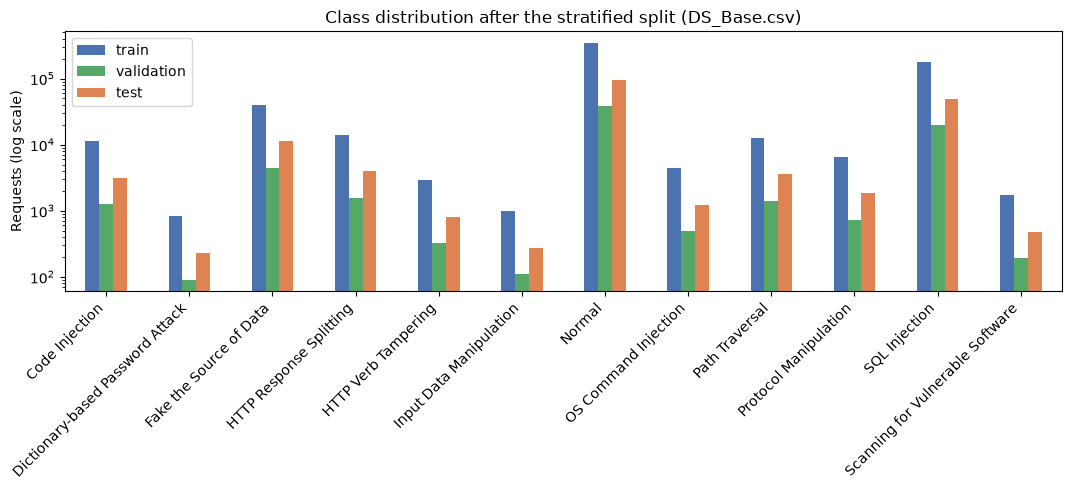

In [3]:
figure, axes = plt.subplots(figsize=(11, 5))
class_distribution.plot.bar(ax=axes, logy=True, color=["#4C72B0", "#55A868", "#DD8452"])
axes.set_title(f"Class distribution after the stratified split ({DATASET_NAME})")
axes.set_ylabel("Requests (log scale)")
axes.tick_params(axis="x", labelrotation=45)
plt.setp(axes.get_xticklabels(), ha="right")
figure.tight_layout()
figure.savefig(RESULTS_DIR / "class-distribution.png", dpi=150)
plt.show()

## Encode the requests and build the model

In [4]:
def encode_requests_as_ascii_codes(
    request_texts: pd.Series, max_characters: int = SEQUENCE_MAX_CHARACTERS
) -> np.ndarray:
    """ASCII code + 1 of the first `max_characters` characters, zero-padded; non-ASCII becomes '?'."""
    encoded_requests = np.zeros((len(request_texts), max_characters), np.uint8)
    for row_index, request_text in enumerate(request_texts):
        ascii_codes = np.frombuffer(
            request_text[:max_characters].encode("ascii", "replace"), np.uint8
        )
        encoded_requests[row_index, : len(ascii_codes)] = ascii_codes + 1
    return encoded_requests


class CnnBiLstmClassifier(nn.Module):
    """Character embedding -> Conv1d + ReLU + max-pool -> 2-layer BiLSTM -> linear classifier."""

    def __init__(self, class_count: int) -> None:
        super().__init__()
        self.character_embedding = nn.Embedding(
            CHARACTER_VOCABULARY_SIZE, CHARACTER_EMBEDDING_SIZE, padding_idx=0
        )
        self.convolution_block = nn.Sequential(
            nn.Conv1d(
                CHARACTER_EMBEDDING_SIZE,
                CONVOLUTION_FILTER_COUNT,
                CONVOLUTION_KERNEL_WIDTH,
                padding=CONVOLUTION_KERNEL_WIDTH // 2,
            ),
            nn.ReLU(),
            nn.MaxPool1d(2),
        )
        self.bidirectional_lstm = nn.LSTM(
            CONVOLUTION_FILTER_COUNT,
            LSTM_HIDDEN_SIZE,
            num_layers=LSTM_LAYER_COUNT,
            bidirectional=True,
            batch_first=True,
        )
        self.classification_head = nn.Linear(2 * LSTM_HIDDEN_SIZE, class_count)

    def forward(self, character_codes: torch.Tensor) -> torch.Tensor:
        embedded_sequence = self.character_embedding(character_codes.long())
        # Conv1d wants (batch, channels, length); the LSTM wants (batch, length, channels).
        convolved_sequence = self.convolution_block(
            embedded_sequence.transpose(1, 2)
        ).transpose(1, 2)
        _, (final_hidden_states, _) = self.bidirectional_lstm(convolved_sequence)
        # The last layer's forward and backward final states.
        return self.classification_head(
            torch.cat([final_hidden_states[-2], final_hidden_states[-1]], dim=1)
        )


@torch.no_grad()
def predict_in_batches(model: nn.Module, character_codes: torch.Tensor) -> np.ndarray:
    """Argmax class ids for every row, predicted in fixed-size batches to bound GPU memory."""
    model.eval()
    predicted_label_batches = [
        model(character_codes[batch_start : batch_start + PREDICTION_BATCH_SIZE])
        .argmax(dim=1)
        .cpu()
        for batch_start in range(0, len(character_codes), PREDICTION_BATCH_SIZE)
    ]
    return torch.cat(predicted_label_batches).numpy()


train_character_codes = torch.from_numpy(
    encode_requests_as_ascii_codes(train_texts)
).to(device)
test_character_codes = torch.from_numpy(encode_requests_as_ascii_codes(test_texts)).to(
    device
)
validation_character_codes = torch.from_numpy(
    encode_requests_as_ascii_codes(validation_texts)
).to(device)
train_label_tensor = torch.from_numpy(train_labels).to(device)
del train_texts, validation_texts, test_texts

cnn_bilstm_classifier = CnnBiLstmClassifier(len(class_names)).to(device)
class_weights = (
    compute_class_weight(
        "balanced", classes=np.arange(len(class_names)), y=train_labels
    )
    ** CLASS_WEIGHT_POWER
)
weighted_loss_function = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32, device=device)
)
optimizer = torch.optim.Adam(cnn_bilstm_classifier.parameters())
learning_rate_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=LEARNING_RATE_DECAY_FACTOR, patience=0
)
cnn_bilstm_classifier

CnnBiLstmClassifier(
  (character_embedding): Embedding(129, 100, padding_idx=0)
  (convolution_block): Sequential(
    (0): Conv1d(100, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (bidirectional_lstm): LSTM(128, 128, num_layers=2, batch_first=True, bidirectional=True)
  (classification_head): Linear(in_features=256, out_features=12, bias=True)
)

## Train

In [5]:
import sys

from tqdm import tqdm  # Plain-text bar: VS Code redraws it in place, no widget needed.

# Early stopping and the LR schedule use the validation split; test scores per epoch
# are recorded only for the training-curve graph and nothing is tuned on them.
LOSS_DISPLAY_EVERY_STEPS = (
    50  # Reading the loss forces a GPU sync, so refresh it only this often.
)
training_history = []
train_sample_count = len(train_label_tensor)
steps_per_epoch = math.ceil(train_sample_count / TRAINING_BATCH_SIZE)
shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
training_start_time = time.monotonic()
best_validation_macro_f1, best_epoch, best_model_state = -1.0, 0, None

for epoch_index in range(TRAINING_EPOCHS):
    cnn_bilstm_classifier.train()
    shuffled_indices = torch.randperm(
        train_sample_count, generator=shuffle_generator
    ).to(device)
    epoch_loss_sum = torch.zeros(
        (), device=device
    )  # Summed on the GPU to avoid a sync every step.
    epoch_label = f"Epoch {epoch_index + 1}/{TRAINING_EPOCHS}"
    with tqdm(
        total=steps_per_epoch,
        desc=epoch_label,
        unit="step",
        file=sys.stdout,
        mininterval=0.5,
        bar_format="{desc} {percentage:3.0f}%|{bar:28}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}{postfix}]",
    ) as progress_bar:
        for step_index in range(steps_per_epoch):
            batch_indices = shuffled_indices[
                step_index * TRAINING_BATCH_SIZE : (step_index + 1)
                * TRAINING_BATCH_SIZE
            ]
            logits = cnn_bilstm_classifier(train_character_codes[batch_indices])
            batch_loss = weighted_loss_function(
                logits, train_label_tensor[batch_indices]
            )
            optimizer.zero_grad(set_to_none=True)
            batch_loss.backward()
            nn.utils.clip_grad_norm_(
                cnn_bilstm_classifier.parameters(), GRADIENT_CLIP_NORM
            )
            optimizer.step()
            epoch_loss_sum += batch_loss.detach()
            progress_bar.update(1)
            if (step_index + 1) % LOSS_DISPLAY_EVERY_STEPS == 0:
                progress_bar.set_postfix(
                    loss=f"{batch_loss.item():.4f}",
                    average_loss=f"{epoch_loss_sum.item() / (step_index + 1):.4f}",
                )

        progress_bar.set_description(f"{epoch_label} evaluating")
        epoch_predictions = predict_in_batches(
            cnn_bilstm_classifier, test_character_codes
        )
        validation_macro_f1 = 100 * f1_score(
            validation_labels,
            predict_in_batches(cnn_bilstm_classifier, validation_character_codes),
            average="macro",
            zero_division=0,
        )
        learning_rate_scheduler.step(validation_macro_f1)
        if validation_macro_f1 > best_validation_macro_f1:
            best_validation_macro_f1, best_epoch = validation_macro_f1, epoch_index + 1
            best_model_state = copy.deepcopy(cnn_bilstm_classifier.state_dict())
        epoch_average_loss = epoch_loss_sum.item() / steps_per_epoch
        if not math.isfinite(epoch_average_loss):
            raise FloatingPointError(
                f"training loss became {epoch_average_loss} in epoch {epoch_index + 1}"
            )
        training_history.append(
            {
                "epoch": epoch_index + 1,
                "train_loss": epoch_average_loss,
                "learning_rate": optimizer.param_groups[0]["lr"],
                "validation_macro_f1": validation_macro_f1,
                "test_accuracy": 100 * accuracy_score(test_labels, epoch_predictions),
                "test_macro_f1": 100
                * f1_score(
                    test_labels, epoch_predictions, average="macro", zero_division=0
                ),
            }
        )
        progress_bar.set_description(f"{epoch_label} done")
        progress_bar.set_postfix(
            average_loss=f"{epoch_average_loss:.4f}",
            accuracy=f"{training_history[-1]['test_accuracy']:.2f}%",
            macro_f1=f"{training_history[-1]['test_macro_f1']:.2f}%",
        )
    log_progress(
        f"finished epoch {epoch_index + 1}/{TRAINING_EPOCHS}: "
        + ", ".join(
            f"{key} {value:.4f}"
            for key, value in training_history[-1].items()
            if key != "epoch"
        )
    )

training_minutes = (time.monotonic() - training_start_time) / 60
if best_model_state is None:
    raise RuntimeError("no epoch produced a validation score")
cnn_bilstm_classifier.load_state_dict(
    best_model_state
)  # Early stopping: keep the best epoch.
log_progress(
    f"kept epoch {best_epoch} (validation macro F1 {best_validation_macro_f1:.2f}%)"
)
training_history = pd.DataFrame(training_history).set_index("epoch")
training_history

Epoch 1/5 done:  100%|████████████████████████████| 9668/9668 [01:35<00:00, 100.93step/s, accuracy=95.04%, average_loss=0.2451, macro_f1=79.01%]
2026-11-19 08:44:03 [DS_Base.csv] finished epoch 1/5: train_loss 0.2451, learning_rate 0.0010, validation_macro_f1 79.6281, test_accuracy 95.0355, test_macro_f1 79.0079
Epoch 2/5 done:  100%|████████████████████████████| 9668/9668 [01:36<00:00, 100.43step/s, accuracy=95.08%, average_loss=0.1820, macro_f1=79.43%]
2026-11-19 08:45:39 [DS_Base.csv] finished epoch 2/5: train_loss 0.1820, learning_rate 0.0010, validation_macro_f1 79.8447, test_accuracy 95.0838, test_macro_f1 79.4275
Epoch 3/5 done:  100%|████████████████████████████| 9668/9668 [01:36<00:00, 100.16step/s, accuracy=96.46%, average_loss=0.1750, macro_f1=80.33%]
2026-11-19 08:47:16 [DS_Base.csv] finished epoch 3/5: train_loss 0.1750, learning_rate 0.0010, validation_macro_f1 80.4686, test_accuracy 96.4552, test_macro_f1 80.3314
Epoch 4/5 done:  100%|████████████████████████████| 9668/9

,train_loss,learning_rate,validation_macro_f1,test_accuracy,test_macro_f1
epoch,,,,,
1,0.245148,0.001,79.628133,95.035465,79.007877
2,0.182043,0.001,79.844733,95.083761,79.427473
3,0.175036,0.001,80.468624,96.455234,80.331362
4,0.171924,0.001,80.735794,95.704036,80.350138
5,0.169810,0.001,82.144440,96.413921,81.747249


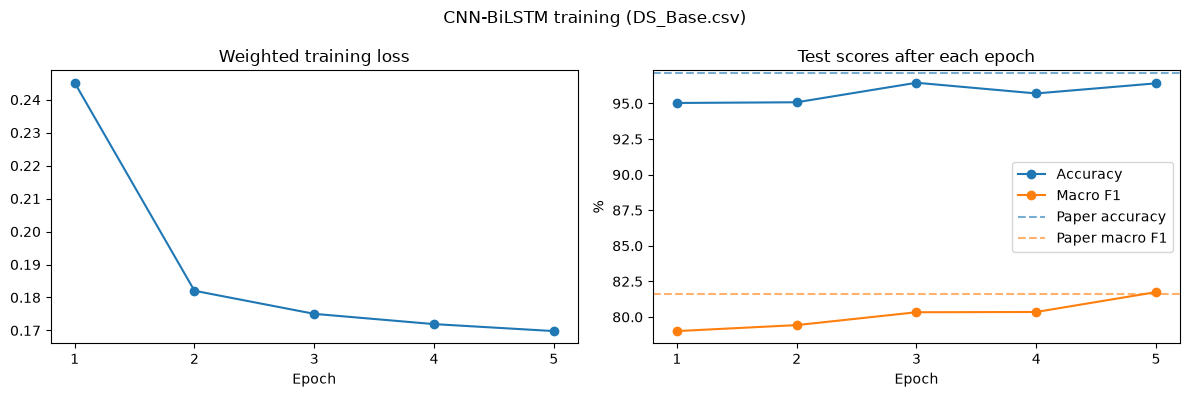

In [6]:
figure, (loss_axes, score_axes) = plt.subplots(1, 2, figsize=(12, 4))
loss_axes.plot(training_history.index, training_history["train_loss"], marker="o")
loss_axes.set_title("Weighted training loss")
loss_axes.set_xlabel("Epoch")
score_axes.plot(
    training_history.index,
    training_history["test_accuracy"],
    marker="o",
    label="Accuracy",
)
score_axes.plot(
    training_history.index,
    training_history["test_macro_f1"],
    marker="o",
    label="Macro F1",
)
score_axes.axhline(
    PAPER_ACCURACY, linestyle="--", color="C0", alpha=0.6, label="Paper accuracy"
)
score_axes.axhline(
    PAPER_MACRO_F1, linestyle="--", color="C1", alpha=0.6, label="Paper macro F1"
)
score_axes.set_title("Test scores after each epoch")
score_axes.set_xlabel("Epoch")
score_axes.set_ylabel("%")
score_axes.legend()
for axes in (loss_axes, score_axes):
    axes.set_xticks(training_history.index)
figure.suptitle(f"CNN-BiLSTM training ({DATASET_NAME})")
figure.tight_layout()
figure.savefig(RESULTS_DIR / "training-history.png", dpi=150)
plt.show()

## Result: comparison with the paper

In [7]:
if torch.cuda.is_available():
    torch.cuda.synchronize()
inference_start_time = time.perf_counter()
predicted_labels = predict_in_batches(cnn_bilstm_classifier, test_character_codes)
inference_ms_per_request = (
    1000 * (time.perf_counter() - inference_start_time) / len(test_labels)
)

our_accuracy = 100 * accuracy_score(test_labels, predicted_labels)
our_macro_f1 = 100 * f1_score(
    test_labels, predicted_labels, average="macro", zero_division=0
)
comparison_with_paper = pd.DataFrame(
    {"ours": [our_accuracy, our_macro_f1], "paper": [PAPER_ACCURACY, PAPER_MACRO_F1]},
    index=["accuracy", "macro_f1"],
)
comparison_with_paper["gap_points"] = (
    comparison_with_paper["ours"] - comparison_with_paper["paper"]
)
comparison_with_paper["within_5_points"] = (
    comparison_with_paper["gap_points"].abs() <= ALLOWED_GAP_PERCENTAGE_POINTS
)
replication_passed = bool(comparison_with_paper["within_5_points"].all())
log_progress(
    f"accuracy {our_accuracy:.2f}% (paper {PAPER_ACCURACY}%), macro F1 {our_macro_f1:.2f}% "
    f"(paper {PAPER_MACRO_F1}%), trained in {training_minutes:.1f} min, "
    f"{inference_ms_per_request:.4f} ms/request, within 5 points: {replication_passed}"
)
comparison_with_paper.round(2)

2026-11-19 08:50:37 [DS_Base.csv] accuracy 96.41% (paper 97.11%), macro F1 81.75% (paper 81.58%), trained in 8.0 min, 0.0444 ms/request, within 5 points: True


,ours,paper,gap_points,within_5_points
accuracy,96.41,97.11,-0.70,True
macro_f1,81.75,81.58,0.17,True


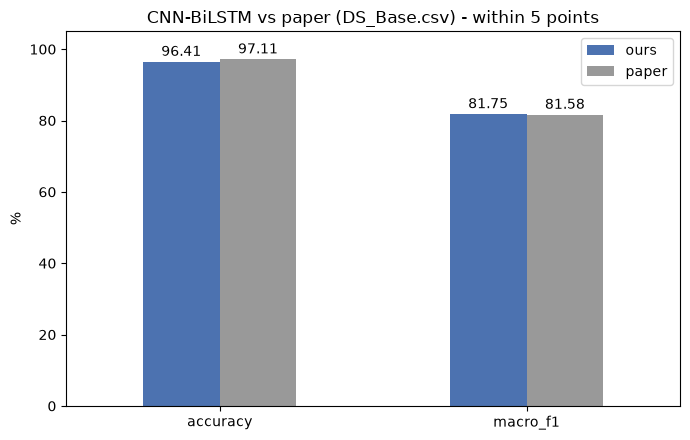

In [8]:
figure, axes = plt.subplots(figsize=(7, 4.5))
comparison_with_paper[["ours", "paper"]].plot.bar(
    ax=axes, rot=0, color=["#4C72B0", "#999999"]
)
for bar_container in axes.containers:
    axes.bar_label(bar_container, fmt="%.2f", padding=2)
axes.set_ylim(0, 105)
axes.set_ylabel("%")
axes.set_title(
    f"CNN-BiLSTM vs paper ({DATASET_NAME}) - "
    + ("within 5 points" if replication_passed else "NOT within 5 points")
)
figure.tight_layout()
figure.savefig(RESULTS_DIR / "comparison-with-paper.png", dpi=150)
plt.show()

## Per-class scores

In [9]:
per_class_report = pd.DataFrame(
    classification_report(
        test_labels,
        predicted_labels,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        digits=4,
        zero_division=0,
        output_dict=True,
    )
).T
per_class_report.round(4)

,precision,recall,f1-score,support
Code Injection,0.9976,0.9326,0.9640,3161.0000
Dictionary-based Password Attack,0.6471,0.9649,0.7746,228.0000
Fake the Source of Data,0.9868,0.9125,0.9482,11197.0000
HTTP Response Splitting,0.9995,0.9629,0.9808,3934.0000
HTTP Verb Tampering,0.9926,0.9938,0.9932,811.0000
Input Data Manipulation,0.0650,0.2996,0.1068,277.0000
Normal,0.9814,0.9854,0.9834,95335.0000
OS Command Injection,0.3188,0.7967,0.4554,1230.0000
Path Traversal,0.9985,0.9389,0.9678,3552.0000
Protocol Manipulation,0.6281,0.6991,0.6617,1831.0000


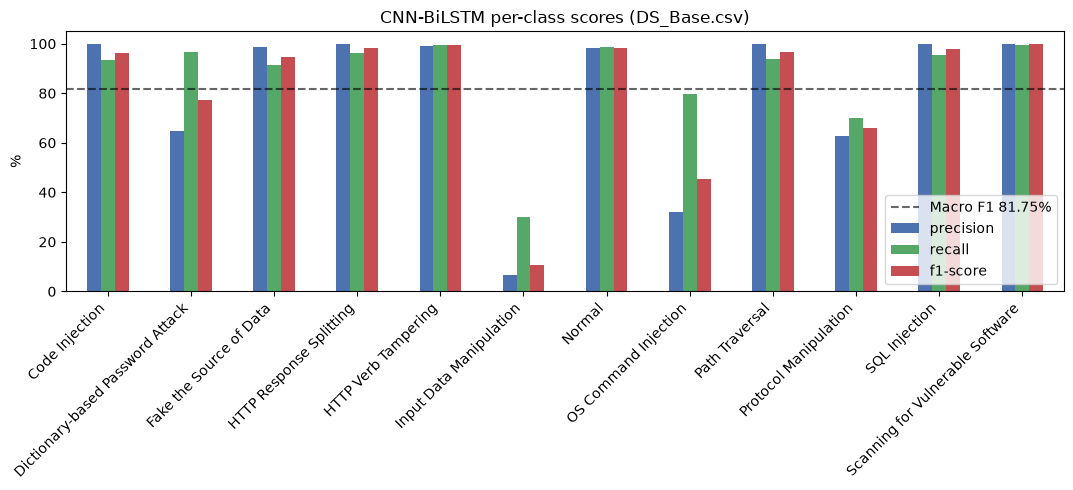

In [10]:
class_scores = (
    per_class_report.loc[class_names, ["precision", "recall", "f1-score"]] * 100
)
figure, axes = plt.subplots(figsize=(11, 5))
class_scores.plot.bar(ax=axes, color=["#4C72B0", "#55A868", "#C44E52"])
axes.axhline(
    our_macro_f1,
    linestyle="--",
    color="black",
    alpha=0.6,
    label=f"Macro F1 {our_macro_f1:.2f}%",
)
axes.set_ylim(0, 105)
axes.set_ylabel("%")
axes.set_title(f"CNN-BiLSTM per-class scores ({DATASET_NAME})")
axes.legend(loc="lower right")
axes.tick_params(axis="x", labelrotation=45)
plt.setp(axes.get_xticklabels(), ha="right")
figure.tight_layout()
figure.savefig(RESULTS_DIR / "per-class-scores.png", dpi=150)
plt.show()

## Confusion matrix

Rows are normalized, like Fig. 7 in the paper.

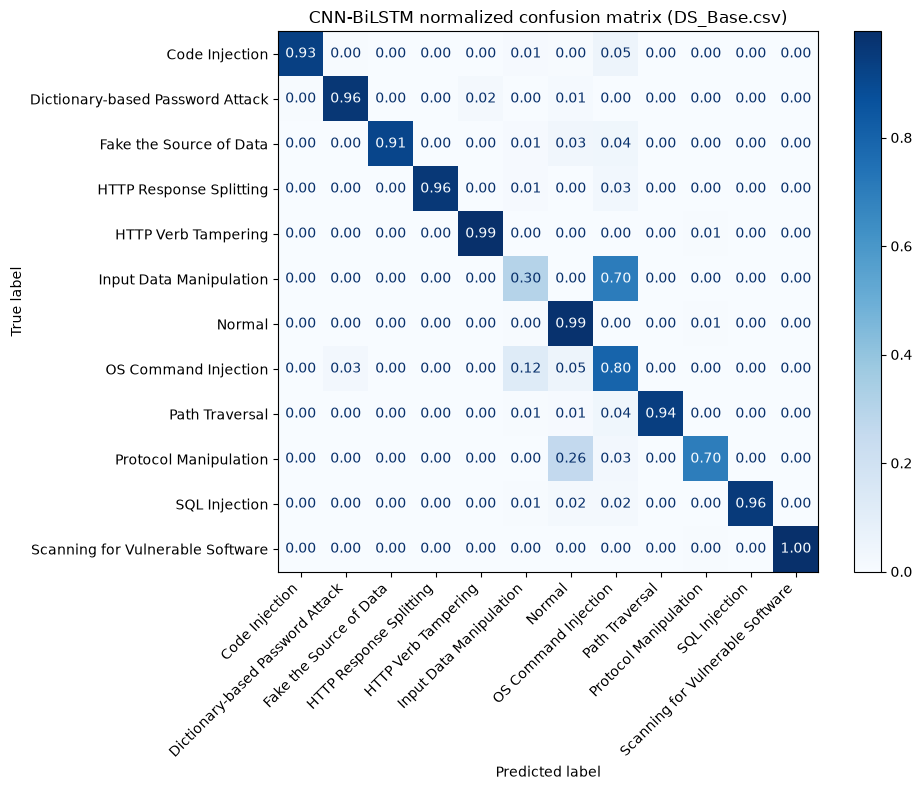

In [11]:
figure, axes = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    test_labels,
    predicted_labels,
    labels=np.arange(len(class_names)),
    display_labels=class_names,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    ax=axes,
    xticks_rotation=45,
)
plt.setp(axes.get_xticklabels(), ha="right")
axes.set_title(f"CNN-BiLSTM normalized confusion matrix ({DATASET_NAME})")
figure.tight_layout()
figure.savefig(RESULTS_DIR / "confusion-matrix.png", dpi=150)
plt.show()

## Save the metrics

In [12]:
metrics_file = RESULTS_DIR / "metrics.json"
metrics = {
    "dataset": DATASET_NAME,
    "model": "CNN-BiLSTM",
    "device": str(device),
    "classes": class_names,
    "paper": {"accuracy": PAPER_ACCURACY, "macro_f1": PAPER_MACRO_F1},
    "ours": {"accuracy": our_accuracy, "macro_f1": our_macro_f1},
    "within_5_points": replication_passed,
    "training_minutes": training_minutes,
    "inference_ms_per_request": inference_ms_per_request,
    "best_epoch": best_epoch,
    "class_weight_power": CLASS_WEIGHT_POWER,
    "training_history": training_history.reset_index().to_dict(orient="records"),
    "per_class_report": per_class_report.to_dict(orient="index"),
}
temporary_file = metrics_file.with_suffix(
    ".json.tmp"
)  # Write then rename, so a crash can't leave half a file.
temporary_file.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
temporary_file.replace(metrics_file)
print("Saved:", metrics_file)
print("Graphs:", ", ".join(sorted(path.name for path in RESULTS_DIR.glob("*.png"))))

Saved: D:\Thesis\project-argus\results\ds-base\metrics.json
Graphs: class-distribution.png, comparison-with-paper.png, confusion-matrix.png, per-class-scores.png, training-history.png


## Summary

Our result next to Table VI of the paper. The replication passes when both gaps are within 5 percentage points.

In [13]:
from IPython.display import Markdown, display

verdict = "PASSED, within 5 points" if replication_passed else "NOT within 5 points"
display(Markdown(f"## Final results: CNN-BiLSTM on {DATASET_NAME} ({verdict})"))

# 1. Table VI comparison. Only accuracy and F1 are checked against the 5-point tolerance:
#    the paper trained on an 8-vCPU CPU server, so its times aren't comparable to a GPU run.
format_minutes = lambda minutes: f"{int(minutes // 60)}:{round(minutes % 60):02d}"
table_vi_comparison = pd.DataFrame(
    {
        "Ours": [
            f"{our_accuracy:.2f}%",
            f"{our_macro_f1:.2f}%",
            format_minutes(training_minutes),
            f"{inference_ms_per_request:.3f}",
        ],
        "Paper": [
            f"{PAPER_ACCURACY:.2f}%",
            f"{PAPER_MACRO_F1:.2f}%",
            PAPER_TRAINING_TIME,
            f"{PAPER_INFERENCE_MS:.3f}",
        ],
        "Gap (points)": [
            f"{our_accuracy - PAPER_ACCURACY:+.2f}",
            f"{our_macro_f1 - PAPER_MACRO_F1:+.2f}",
            "",
            "",
        ],
        "Within 5 points": [
            str(abs(our_accuracy - PAPER_ACCURACY) <= ALLOWED_GAP_PERCENTAGE_POINTS),
            str(abs(our_macro_f1 - PAPER_MACRO_F1) <= ALLOWED_GAP_PERCENTAGE_POINTS),
            "",
            "",
        ],
    },
    index=["Accuracy", "F1-score (macro)", "Train time (HH:MM)", "Inference time (ms)"],
)
display(Markdown("### 1. Comparison with Table VI of the paper"))
display(table_vi_comparison)

# 2. How this run was set up, so the result can be reproduced.
run_details = pd.DataFrame(
    {
        "Value": [
            DATASET_NAME,
            (
                f"{len(train_labels):,} train / {len(validation_labels):,} validation / {len(test_labels):,} test "
                f"(stratified {1 - TEST_FRACTION:.0%}/{TEST_FRACTION:.0%}, validation {VALIDATION_FRACTION:.0%} of train, seed {RANDOM_SEED})"
            ),
            f"{len(class_names)}",
            str(device),
            (
                f"{TRAINING_EPOCHS} epochs (kept epoch {best_epoch} by validation macro F1), batch {TRAINING_BATCH_SIZE}, "
                f"Adam (default learning rate, halved on plateau), class weights balanced ** {CLASS_WEIGHT_POWER}, "
                f"gradient clip {GRADIENT_CLIP_NORM}"
            ),
            f"first {SEQUENCE_MAX_CHARACTERS} characters as ASCII codes, embedding {CHARACTER_EMBEDDING_SIZE}",
            f"Conv1D ({CONVOLUTION_FILTER_COUNT} filters, kernel {CONVOLUTION_KERNEL_WIDTH}) + {LSTM_LAYER_COUNT}-layer BiLSTM ({LSTM_HIDDEN_SIZE} units)",
            f"{format_minutes(training_minutes)} ({training_minutes:.1f} min)",
            f"{inference_ms_per_request:.4f} ms per request (batched)",
        ]
    },
    index=[
        "Dataset",
        "Requests",
        "Classes",
        "Device",
        "Training",
        "Input",
        "Model",
        "Train time",
        "Inference time",
    ],
)
display(Markdown("### 2. Run details"))
display(run_details)

# 3. Test scores after each epoch (not in Table VI).
display(Markdown("### 3. Training history (not in Table VI)"))
display(
    training_history.style.format(
        {
            "train_loss": "{:.4f}",
            "learning_rate": "{:.1e}",
            "validation_macro_f1": "{:.2f}%",
            "test_accuracy": "{:.2f}%",
            "test_macro_f1": "{:.2f}%",
        }
    )
)

# 4. Overall precision, recall and F1 (the paper uses them but reports only F1 per model).
display(
    Markdown(
        "### 4. Overall precision, recall and F1 (precision and recall not in Table VI)"
    )
)
display(
    (
        per_class_report.loc[
            ["macro avg", "weighted avg"], ["precision", "recall", "f1-score"]
        ]
        * 100
    ).style.format("{:.2f}%")
)

# 5. Per-class scores, weakest F1 first.
display(Markdown("### 5. Per-class report, weakest F1 first (not in Table VI)"))
display(
    per_class_report.loc[class_names]
    .sort_values("f1-score")
    .style.format(
        {
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1-score": "{:.4f}",
            "support": "{:,.0f}",
        }
    )
)

# 6. Where the model goes wrong: the most frequent (true class -> predicted class) mistakes.
MISCLASSIFICATIONS_SHOWN = 10
mistake_pairs = pd.DataFrame(
    {
        "True class": np.asarray(class_names)[test_labels],
        "Predicted as": np.asarray(class_names)[predicted_labels],
    }
)
mistake_pairs = mistake_pairs[
    mistake_pairs["True class"] != mistake_pairs["Predicted as"]
]
top_mistakes = (
    mistake_pairs.value_counts()
    .head(MISCLASSIFICATIONS_SHOWN)
    .rename("Requests")
    .reset_index()
)
class_support = pd.Series(
    np.bincount(test_labels, minlength=len(class_names)), index=class_names
)
top_mistakes["% of true class"] = (
    100
    * top_mistakes["Requests"]
    / class_support[top_mistakes["True class"]].to_numpy()
)
display(
    Markdown(
        f"### 6. Top {MISCLASSIFICATIONS_SHOWN} misclassifications ({len(mistake_pairs):,} of {len(test_labels):,} test requests wrong)"
    )
)
display(
    top_mistakes.style.format({"Requests": "{:,}", "% of true class": "{:.2f}%"}).hide(
        axis="index"
    )
)

# 7. Plain-language reading of the numbers above.
class_f1 = per_class_report.loc[class_names, "f1-score"]
class_precision = per_class_report.loc[class_names, "precision"]
notes = [
    (
        f"Accuracy is {our_accuracy:.2f}% against the paper's {PAPER_ACCURACY:.2f}% ({our_accuracy - PAPER_ACCURACY:+.2f} points), "
        f"and macro F1 is {our_macro_f1:.2f}% against {PAPER_MACRO_F1:.2f}% ({our_macro_f1 - PAPER_MACRO_F1:+.2f} points): **{verdict}**."
    ),
    f"Weakest class: **{class_f1.idxmin()}** (F1 {class_f1.min():.4f}); strongest: **{class_f1.idxmax()}** (F1 {class_f1.max():.4f}).",
    (
        f"Lowest precision: **{class_precision.idxmin()}** ({class_precision.min():.4f}). The class-weighted loss "
        "favours recall on rare classes, which can cost precision and so macro F1."
    ),
]
if top_mistakes.empty:
    notes.append("No test request was misclassified.")
else:
    worst = top_mistakes.iloc[0]
    notes.append(
        f"Most common mistake: {worst['True class']} predicted as {worst['Predicted as']} "
        f"({worst['Requests']:,} requests, {worst['% of true class']:.2f}% of that class)."
    )
notes.append(
    f"Train and inference times aren't comparable to the paper's: it trained on an 8-vCPU CPU server, this run used {device}."
)
display(Markdown("### 7. Notes\n\n" + "\n".join(f"- {note}" for note in notes)))

## Final results: CNN-BiLSTM on DS_Base.csv (PASSED, within 5 points)

### 1. Comparison with Table VI of the paper

,Ours,Paper,Gap (points),Within 5 points
Accuracy,96.41%,97.11%,-0.70,True
F1-score (macro),81.75%,81.58%,+0.17,True
Train time (HH:MM),0:08,4:19,,
Inference time (ms),0.044,0.727,,


### 2. Run details

,Value
Dataset,DS_Base.csv
Requests,"618,690 train / 68,744 validation / 171,859 te..."
Classes,12
Device,cuda
Training,5 epochs (kept epoch 5 by validation macro F1)...
Input,"first 100 characters as ASCII codes, embedding..."
Model,"Conv1D (128 filters, kernel 5) + 2-layer BiLST..."
Train time,0:08 (8.0 min)
Inference time,0.0444 ms per request (batched)


### 3. Training history (not in Table VI)

... (4 outputs left out)

,precision,recall,f1-score,support
Input Data Manipulation,0.0650,0.2996,0.1068,277
OS Command Injection,0.3188,0.7967,0.4554,"1,230"
Protocol Manipulation,0.6281,0.6991,0.6617,"1,831"
Dictionary-based Password Attack,0.6471,0.9649,0.7746,228
Fake the Source of Data,0.9868,0.9125,0.9482,"11,197"
Code Injection,0.9976,0.9326,0.9640,"3,161"
Path Traversal,0.9985,0.9389,0.9678,"3,552"
SQL Injection,0.9988,0.9558,0.9768,"49,820"
HTTP Response Splitting,0.9995,0.9629,0.9808,"3,934"
Normal,0.9814,0.9854,0.9834,"95,335"


### 6. Top 10 misclassifications (6,163 of 171,859 test requests wrong)

True class,Predicted as,Requests,% of true class
SQL Injection,OS Command Injection,955,1.92%
SQL Injection,Normal,815,1.64%
Normal,Protocol Manipulation,710,0.74%
Protocol Manipulation,Normal,472,25.78%
Normal,Input Data Manipulation,450,0.47%
Fake the Source of Data,OS Command Injection,434,3.88%
Fake the Source of Data,Normal,373,3.33%
SQL Injection,Input Data Manipulation,372,0.75%
Input Data Manipulation,OS Command Injection,194,70.04%
OS Command Injection,Input Data Manipulation,153,12.44%


### 7. Notes

- Accuracy is 96.41% against the paper's 97.11% (-0.70 points), and macro F1 is 81.75% against 81.58% (+0.17 points): **PASSED, within 5 points**.
- Weakest class: **Input Data Manipulation** (F1 0.1068); strongest: **Scanning for Vulnerable Software** (F1 0.9969).
- Lowest precision: **Input Data Manipulation** (0.0650). The class-weighted loss favours recall on rare classes, which can cost precision and so macro F1.
- Most common mistake: SQL Injection predicted as OS Command Injection (955 requests, 1.92% of that class).
- Train and inference times aren't comparable to the paper's: it trained on an 8-vCPU CPU server, this run used cuda.